# Análisis No Supervisado — Postulantes UNI (2021–2024)

**Dataset:** `Datos_postulantes_UNI.xlsx` — 42,516 registros · 22 variables  
**Objetivo:** Identificar perfiles de postulantes comparando dos enfoques:

| | Modelo A | Modelo B |
|--|----------|----------|
| **Algoritmo** | K-Means directo | PCA automático + K-Means |
| **Features** | 11 (perfil base + modalidad) | Todas las variables disponibles → limpieza de correlaciones → PCA |
| **Facultad** | No incluida | Sí — reemplaza ESPECIALIDAD como 11 dummies |
| **Correlaciones** | No aplica | Heatmap → eliminar variables redundantes (umbral >0.85) |

**Codificación de sexo:** `SEXO_ = 1` → Masculino | `SEXO_ = 0` → Femenino

---
> **Etapas:** Carga → Limpieza → Feature Engineering → EDA → Modelo A (K-Means) → Modelo B (limpieza correlaciones + PCA + K-Means) → Comparación → Conclusiones

## 1. Importación de Librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

PALETTE  = ['#1a3a5c','#2e86ab','#a23b72','#f18f01','#c73e1d','#3b7d4f','#7b4ea0','#e86a10']
COLOR_SI = '#2e86ab'
COLOR_NO = '#e05c5c'

plt.rcParams.update({
    'figure.dpi':110, 'axes.titlesize':12, 'axes.labelsize':10,
    'axes.grid':True, 'grid.alpha':0.35,
    'figure.facecolor':'white', 'axes.facecolor':'#f8f9fa',
})
print('Librerías cargadas correctamente')

Librerías cargadas correctamente


## 2. Carga y Exploración Inicial

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
ruta = "/content/drive/MyDrive/Portafolio/Análisis Clustering UNI/Proyecto_UNI_corregido.ipynb"
df = pd.read_excel(ruta)

In [ ]:

print(f'Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas')
print(f'Período    : {df["ANIO_POSTULA"].min()} - {df["ANIO_POSTULA"].max()}')
print(f'Tasa global de ingreso: {(df["INGRESO"]=="SI").mean()*100:.2f}%')
print()
print('DISTRIBUCIÓN DE INGRESO:')
for k, v in df['INGRESO'].value_counts().items():
    bar = chr(9608) * int(v/len(df)*50)
    print(f'  {k}: {v:>6,}  ({v/len(df)*100:.1f}%)  {bar}')
print()
print('DISTRIBUCIÓN DE SEXO:')
for k, v in df['SEXO'].value_counts().items():
    print(f'  {k}: {v:>6,}  ({v/len(df)*100:.1f}%)')
print()
print('Nulos por columna:')
nulos = df.isna().sum()
print(nulos[nulos>0].sort_values(ascending=False).to_string())

Dimensiones: 42,516 filas x 22 columnas
Período    : 2021 - 2024
Tasa global de ingreso: 16.42%

DISTRIBUCIÓN DE INGRESO:
  NO: 35,535  (83.6%)  █████████████████████████████████████████
  SI:  6,981  (16.4%)  ████████

DISTRIBUCIÓN DE SEXO:
  MASCULINO: 32,419  (76.3%)
  FEMENINO: 10,097  (23.7%)

Nulos por columna:
COLEGIO_PAIS       23574
COLEGIO_DIST         228
COLEGIO_PROV         228
COLEGIO_DEPA         226
NACIMIENTO_DIST      203
NACIMIENTO_PROV      202
NACIMIENTO_DEPA      202
ESPECIALIDAD          55
CALIF_FINAL           24


## 3. Limpieza y Feature Engineering

In [ ]:
# ── Normalización de campos categóricos ───────────────────────────────────
for col in ['ESPECIALIDAD','DOMICILIO_DEPA','SEXO','INGRESO',
            'NACIMIENTO_PAIS','MODALIDAD','COLEGIO_DEPA']:
    df[col] = df[col].astype(str).str.strip().str.upper()

# ── Exclusión de extranjeros ───────────────────────────────────────────────
df_peru = df[df['NACIMIENTO_PAIS']=='PERÚ'].copy()
print(f'Registros originales : {len(df):,}')
print(f'Nacidos en Perú      : {len(df_peru):,}  ({len(df_peru)/len(df)*100:.2f}%)')
print(f'Excluidos            : {len(df)-len(df_peru):,}')

# ── Variables derivadas ────────────────────────────────────────────────────
# EDAD_ reemplaza a ANIO_NACIMIENTO y ANIO_POSTULA
# ANIOS_DESDE_COLEGIO_ reemplaza a COLEGIO_ANIO_EGRESO y ANIO_POSTULA
df_peru['EDAD_']                = df_peru['ANIO_POSTULA'] - df_peru['ANIO_NACIMIENTO']
df_peru['ANIOS_DESDE_COLEGIO_'] = df_peru['ANIO_POSTULA'] - df_peru['COLEGIO_ANIO_EGRESO']
df_peru['DOMICILIO_DEPA_']      = (df_peru['DOMICILIO_DEPA']=='LIMA').astype(int)
df_peru['COLEGIO_LIMA_']        = (df_peru['COLEGIO_DEPA']  =='LIMA').astype(int)
df_peru['SEXO_']                = (df_peru['SEXO']=='MASCULINO').astype(int)  # 1=Masc, 0=Fem
df_peru['INGRESO_']             = (df_peru['INGRESO']=='SI').astype(int)

print()
print('Verificación codificación SEXO_ (Masculino=1, Femenino=0):')
for sexo, val in df_peru.groupby('SEXO')['SEXO_'].mean().items():
    print(f'  {sexo}: SEXO_ = {val:.0f}')

# ── Modalidad simplificada ─────────────────────────────────────────────────
def simplifica_modalidad(m):
    m = str(m).upper()
    if m.startswith('ORDINARIO'):    return 'Ordinario'
    if 'CEPRE' in m:                 return 'CEPRE'
    if 'ESCOLAR' in m:               return 'Escolar'
    if 'BECA' in m or 'TALEN' in m:  return 'Beca18'
    if 'DOS PRIMEROS' in m:          return 'DosPrimeros'
    return 'Otro'

df_peru['MODALIDAD_SIMPLE'] = df_peru['MODALIDAD'].apply(simplifica_modalidad)
modal_dummies = pd.get_dummies(df_peru['MODALIDAD_SIMPLE'], prefix='MOD', dtype=int)

# ── ESPECIALIDAD → FACULTAD (11 facultades UNI) ───────────────────────────
facultad_map = {
    'ARQUITECTURA':'FAU',
    'FISICA':'FC','MATEMATICA':'FC','QUIMICA':'FC',
    'INGENIERIA FISICA':'FC','CIENCIA DE LA COMPUTACION':'FC',
    'INGENIERIA AMBIENTAL':'FIA','INGENIERIA SANITARIA':'FIA',
    'INGENIERIA DE HIGIENE Y SEGURIDAD INDUSTRIAL':'FIA',
    'INGENIERIA CIVIL':'FIC',
    'INGENIERIA ECONOMICA':'FIECS','INGENIERIA ESTADISTICA':'FIECS',
    'INGENIERIA GEOLOGICA':'FIGMM','INGENIERIA DE MINAS':'FIGMM',
    'INGENIERIA METALURGICA':'FIGMM',
    'INGENIERIA INDUSTRIAL':'FIIS','INGENIERIA DE SISTEMAS':'FIIS',
    'INGENIERIA DE SOFTWARE':'FIIS','INGENIERIA DE CIBERSEGURIDAD':'FIIS',
    'INGENIERIA MECANICA':'FIM','INGENIERIA MECANICA-ELECTRICA':'FIM',
    'INGENIERIA MECATRONICA':'FIM','INGENIERIA NAVAL':'FIM',
    'INGENIERIA ELECTRICA':'FIEEE','INGENIERIA ELECTRONICA':'FIEEE',
    'INGENIERIA DE TELECOMUNICACIONES':'FIEEE',
    'INGENIERIA QUIMICA':'FIQT','INGENIERIA TEXTIL':'FIQT',
    'INGENIERIA PETROQUIMICA':'FIQT',
    'INGENIERIA DE PETROLEO Y GAS NATURAL':'FIPGN',
}
df_peru['ESP_NORM'] = (df_peru['ESPECIALIDAD']
                       .str.normalize('NFKD')
                       .str.encode('ascii',errors='ignore')
                       .str.decode('ascii'))
df_peru['FACULTAD'] = df_peru['ESP_NORM'].map(facultad_map)
fac_dummies = pd.get_dummies(df_peru['FACULTAD'], prefix='FAC', dtype=int)

df_model = pd.concat([df_peru, fac_dummies, modal_dummies], axis=1)

print()
print(f'Especialidades originales -> {df_peru["ESPECIALIDAD"].nunique()} carreras')
print(f'Agrupadas en             -> {df_peru["FACULTAD"].nunique()} facultades')

Registros originales : 42,516
Nacidos en Perú      : 42,285  (99.46%)
Excluidos            : 231

Verificación codificación SEXO_ (Masculino=1, Femenino=0):
  FEMENINO: SEXO_ = 0
  MASCULINO: SEXO_ = 1

Especialidades originales -> 31 carreras
Agrupadas en             -> 11 facultades


In [ ]:
# ── Limpieza de valores inválidos ──────────────────────────────────────────
n0 = len(df_model)
df_model = df_model.dropna(subset=['CALIF_FINAL'])
df_model = df_model[df_model['ANIOS_DESDE_COLEGIO_'] >= 0]
df_model = df_model[(df_model['EDAD_'] >= 14) & (df_model['EDAD_'] <= 45)]
df_model = df_model[df_model['ANIOS_DESDE_COLEGIO_'] <= 25]
n1 = len(df_model)

print(f'Registros antes  : {n0:,}')
print(f'Registros después: {n1:,}  ({n1/n0*100:.1f}% conservado)')
print(f'Eliminados       : {n0-n1:,}  ({(n0-n1)/n0*100:.2f}%)')
print(f'Tasa de ingreso  : {df_model["INGRESO_"].mean()*100:.2f}%')

Registros antes  : 42,285
Registros después: 42,165  (99.7% conservado)
Eliminados       : 120  (0.28%)
Tasa de ingreso  : 16.38%


## 4. Definición de Features por Modelo

### Variables eliminadas desde el inicio (ambos modelos)

| Variable eliminada | Motivo |
|--------------------|--------|
| `ANIO_POSTULA` | Reemplazada por `EDAD_` (año postula - año nacimiento) |
| `CICLO_POSTULA` | Baja relevancia para el perfil del postulante |
| `ANIO_NACIMIENTO` | Reemplazada por `EDAD_` |
| `COLEGIO_ANIO_EGRESO` | Reemplazada por `ANIOS_DESDE_COLEGIO_` |
| `ESPECIALIDAD` | Reemplazada por `FACULTAD` (Modelo B) |

### Features por modelo

| # | Variable | Modelo A | Modelo B (candidata) |
|---|----------|----------|----------------------|
| 1 | `CALIF_FINAL` | ✅ | ✅ |
| 2 | `EDAD_` | ✅ | ✅ |
| 3 | `ANIOS_DESDE_COLEGIO_` | ❌ (alta corr. con EDAD_) | ✅ candidata → revisar heatmap |
| 4 | `DOMICILIO_DEPA_` | ✅ | ✅ |
| 5 | `COLEGIO_LIMA_` | ✅ | ✅ |
| 6 | `SEXO_` | ✅ | ✅ |
| 7–12 | `MOD_*` (6 dummies modalidad) | ✅ | ✅ |
| 13–23 | `FAC_*` (11 dummies facultad) | ❌ | ✅ reemplaza ESPECIALIDAD |

> En el **Modelo B** se parte de todas las variables candidatas y el heatmap determina  
> cuáles se eliminan por alta correlación (umbral > 0.85).

In [ ]:
fac_cols   = [c for c in df_model.columns if c.startswith('FAC_')]
modal_cols = [c for c in df_model.columns if c.startswith('MOD_')]

# ── Modelo A: 11 features fijas (sin facultad, sin ANIOS_DESDE_COLEGIO_) ──
features_A = (['CALIF_FINAL','EDAD_','DOMICILIO_DEPA_','COLEGIO_LIMA_','SEXO_']
               + modal_cols)

# ── Modelo B: todas las variables candidatas (antes del filtro de correlación)
features_B_candidatas = (['CALIF_FINAL','EDAD_','ANIOS_DESDE_COLEGIO_',
                           'DOMICILIO_DEPA_','COLEGIO_LIMA_','SEXO_']
                          + modal_cols + fac_cols)

df_clean = df_model[features_B_candidatas + ['INGRESO_','FACULTAD','SEXO']].dropna().copy()

print(f'Dataset final : {df_clean.shape[0]:,} registros')
print(f'Modelo A      : {len(features_A)} features (fijas)')
print(f'Modelo B      : {len(features_B_candidatas)} features candidatas (antes de filtro correlación)')
print()
print(f'Modelo A features: {features_A}')
print()
print(f'Modelo B candidatas base    : CALIF_FINAL, EDAD_, ANIOS_DESDE_COLEGIO_, DOM.LIMA, COLE.LIMA, SEXO_')
print(f'Modelo B dummies modalidad  : {modal_cols}')
print(f'Modelo B dummies facultad   : {fac_cols}')
print()
print(f'SEXO_=1 (Masculino): {(df_clean["SEXO_"]==1).sum():,} ({(df_clean["SEXO_"]==1).mean()*100:.1f}%)')
print(f'SEXO_=0 (Femenino) : {(df_clean["SEXO_"]==0).sum():,} ({(df_clean["SEXO_"]==0).mean()*100:.1f}%)')

Dataset final : 42,119 registros
Modelo A      : 11 features (fijas)
Modelo B      : 23 features candidatas (antes de filtro correlación)

Modelo A features: ['CALIF_FINAL', 'EDAD_', 'DOMICILIO_DEPA_', 'COLEGIO_LIMA_', 'SEXO_', 'MOD_Beca18', 'MOD_CEPRE', 'MOD_DosPrimeros', 'MOD_Escolar', 'MOD_Ordinario', 'MOD_Otro']

Modelo B candidatas base    : CALIF_FINAL, EDAD_, ANIOS_DESDE_COLEGIO_, DOM.LIMA, COLE.LIMA, SEXO_
Modelo B dummies modalidad  : ['MOD_Beca18', 'MOD_CEPRE', 'MOD_DosPrimeros', 'MOD_Escolar', 'MOD_Ordinario', 'MOD_Otro']
Modelo B dummies facultad   : ['FAC_FAU', 'FAC_FC', 'FAC_FIA', 'FAC_FIC', 'FAC_FIECS', 'FAC_FIEEE', 'FAC_FIGMM', 'FAC_FIIS', 'FAC_FIM', 'FAC_FIPGN', 'FAC_FIQT']

SEXO_=1 (Masculino): 32,097 (76.2%)
SEXO_=0 (Femenino) : 10,022 (23.8%)


## 5. Análisis Exploratorio (EDA)

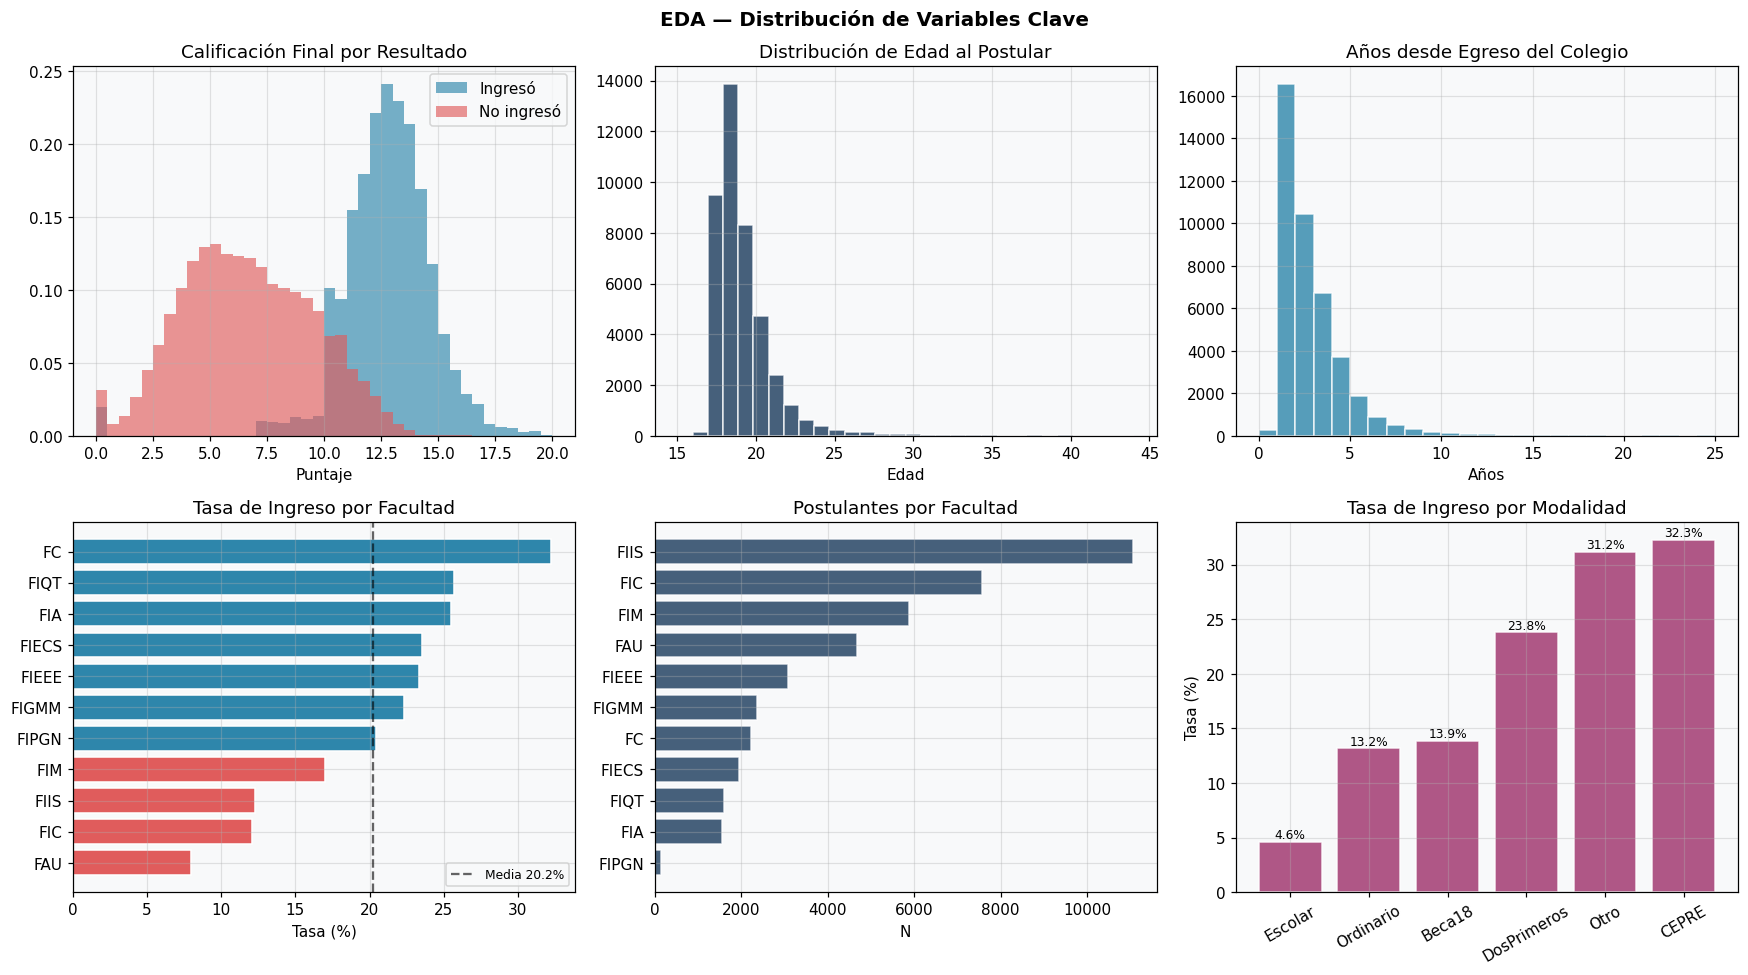

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('EDA — Distribución de Variables Clave', fontsize=13, fontweight='bold')

for lbl, col, label in [('SI',COLOR_SI,'Ingresó'),('NO',COLOR_NO,'No ingresó')]:
    axes[0,0].hist(df_model[df_model['INGRESO']==lbl]['CALIF_FINAL'],
                   bins=40, alpha=0.65, color=col, label=label, density=True)
axes[0,0].set_title('Calificación Final por Resultado')
axes[0,0].set_xlabel('Puntaje'); axes[0,0].legend()

axes[0,1].hist(df_model['EDAD_'], bins=30, color=PALETTE[0], alpha=0.8, edgecolor='white')
axes[0,1].set_title('Distribución de Edad al Postular'); axes[0,1].set_xlabel('Edad')

axes[0,2].hist(df_model['ANIOS_DESDE_COLEGIO_'], bins=25, color=PALETTE[1], alpha=0.8, edgecolor='white')
axes[0,2].set_title('Años desde Egreso del Colegio'); axes[0,2].set_xlabel('Años')

tasa_fac   = df_model.groupby('FACULTAD')['INGRESO_'].mean().sort_values()*100
colors_fac = [COLOR_SI if v>=tasa_fac.mean() else COLOR_NO for v in tasa_fac.values]
axes[1,0].barh(tasa_fac.index, tasa_fac.values, color=colors_fac, edgecolor='white')
axes[1,0].axvline(tasa_fac.mean(), color='black', linestyle='--', alpha=0.6,
                  label=f'Media {tasa_fac.mean():.1f}%')
axes[1,0].set_title('Tasa de Ingreso por Facultad'); axes[1,0].set_xlabel('Tasa (%)')
axes[1,0].legend(fontsize=8)

post_fac = df_model['FACULTAD'].value_counts().sort_values()
axes[1,1].barh(post_fac.index, post_fac.values, color=PALETTE[0], alpha=0.8, edgecolor='white')
axes[1,1].set_title('Postulantes por Facultad'); axes[1,1].set_xlabel('N')

tasa_mod = df_model.groupby('MODALIDAD_SIMPLE')['INGRESO_'].mean().sort_values()*100
axes[1,2].bar(tasa_mod.index, tasa_mod.values, color=PALETTE[2], alpha=0.85, edgecolor='white')
for i, v in enumerate(tasa_mod.values):
    axes[1,2].text(i, v+0.3, f'{v:.1f}%', ha='center', fontsize=8)
axes[1,2].set_title('Tasa de Ingreso por Modalidad')
axes[1,2].set_ylabel('Tasa (%)'); axes[1,2].tick_params(axis='x', rotation=30)

plt.tight_layout(); plt.show()

## 6. Modelo A — K-Means Directo (11 features, sin facultad)

K-Means aplicado directamente sobre las **11 features** escaladas.  
El perfil se basa en calificación, edad, domicilio, colegio, sexo y modalidad.  
No incluye la especialidad ni la facultad.

In [ ]:
scaler_A = StandardScaler()
X_A = scaler_A.fit_transform(df_clean[features_A].values)
y   = df_clean['INGRESO_'].values

K_range = range(2, 11)
inertias_A, silhouettes_A, db_A_list = [], [], []

print(f'{"K":>3} {"Inercia":>12} {"Silhouette":>12} {"Davies-Bouldin":>16}')
print('-'*45)

for k in K_range:
    km  = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    lbs = km.fit_predict(X_A)
    inertias_A.append(km.inertia_)
    silhouettes_A.append(silhouette_score(X_A, lbs, sample_size=5000, random_state=42))
    db_A_list.append(davies_bouldin_score(X_A, lbs))
    print(f'{k:>3} {km.inertia_:>12,.0f} {silhouettes_A[-1]:>12.4f} {db_A_list[-1]:>16.4f}')

  K      Inercia   Silhouette   Davies-Bouldin
---------------------------------------------
  2      391,509       0.2552           2.0311
  3      333,627       0.3130           1.6591
  4      289,804       0.3518           1.2042
  5      242,710       0.3715           0.9970
  6      205,399       0.3906           0.9699
  7      165,156       0.3974           0.8942
  8      143,630       0.3965           0.8458
  9      128,078       0.4288           0.8345
 10      117,933       0.4437           0.9380


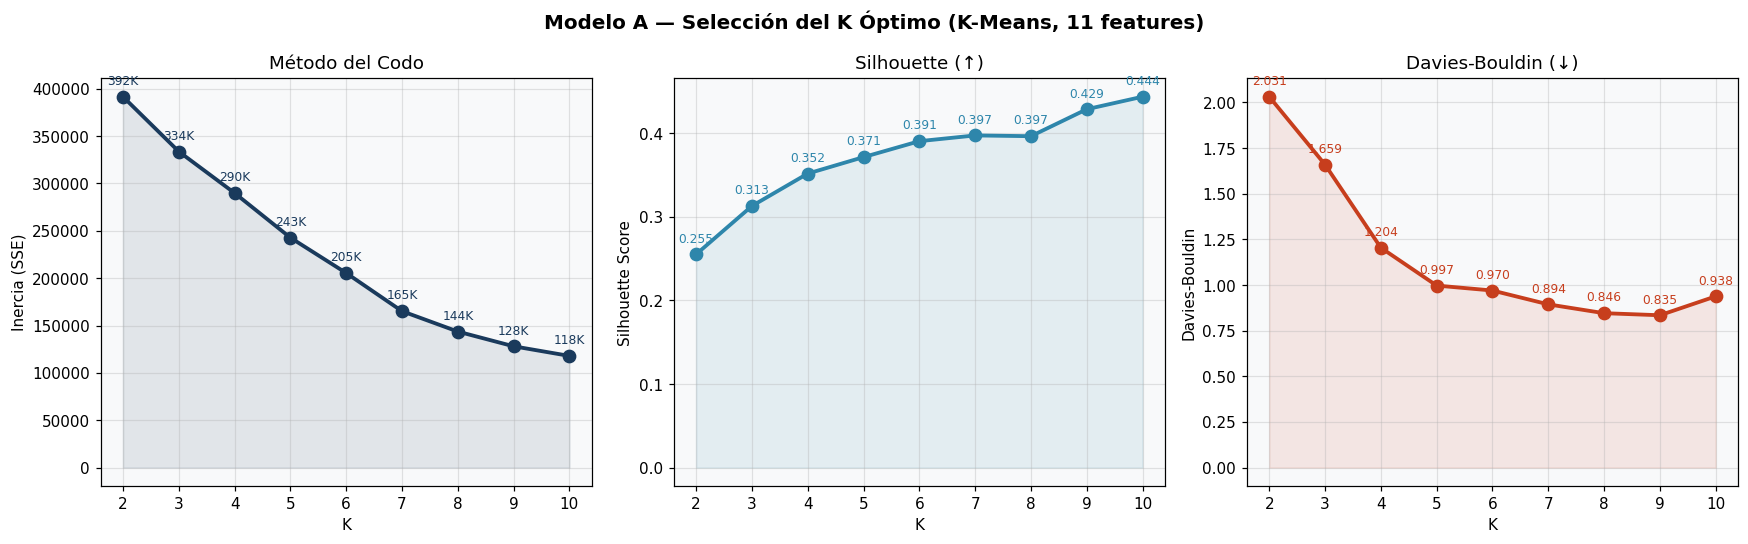

In [ ]:
k_vals = list(K_range)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Modelo A — Selección del K Óptimo (K-Means, 11 features)',
             fontsize=13, fontweight='bold')

for ax, vals, ylabel, title, color in [
    (axes[0], inertias_A,    'Inercia (SSE)',    'Método del Codo',  PALETTE[0]),
    (axes[1], silhouettes_A, 'Silhouette Score', 'Silhouette (↑)',    PALETTE[1]),
    (axes[2], db_A_list,     'Davies-Bouldin',   'Davies-Bouldin (↓)',PALETTE[4]),
]:
    ax.plot(k_vals, vals, 'o-', color=color, linewidth=2.5, markersize=8)
    ax.fill_between(k_vals, vals, alpha=0.1, color=color)
    ax.set_xlabel('K'); ax.set_ylabel(ylabel); ax.set_title(title)
    for k, v in zip(k_vals, vals):
        lbl = f'{v/1000:.0f}K' if ylabel=='Inercia (SSE)' else f'{v:.3f}'
        ax.annotate(lbl, (k,v), textcoords='offset points',
                    xytext=(0,8), ha='center', fontsize=8, color=color)

plt.tight_layout(); plt.show()

In [ ]:
K_OPT_A = 4   # Ajustar según gráficos anteriores

km_A = KMeans(n_clusters=K_OPT_A, random_state=42, n_init=20, max_iter=500)
df_clean['CLUSTER_A'] = km_A.fit_predict(X_A)

sil_A = silhouette_score(X_A, df_clean['CLUSTER_A'], sample_size=8000, random_state=42)
db_A  = davies_bouldin_score(X_A, df_clean['CLUSTER_A'])
ch_A  = calinski_harabasz_score(X_A, df_clean['CLUSTER_A'])

print(f'MÉTRICAS MODELO A (K-Means, 11 features, K={K_OPT_A}):')
print(f'  Silhouette Score  : {sil_A:.4f}')
print(f'  Davies-Bouldin    : {db_A:.4f}')
print(f'  Calinski-Harabasz : {ch_A:.1f}')
print()
for c, n in df_clean['CLUSTER_A'].value_counts().sort_index().items():
    print(f'  Cluster {c}: {n:>6,}  ({n/len(df_clean)*100:.1f}%)')

MÉTRICAS MODELO A (K-Means, 11 features, K=4):
  Silhouette Score  : 0.3502
  Davies-Bouldin    : 1.2042
  Calinski-Harabasz : 8404.7

  Cluster 0:  7,190  (17.1%)
  Cluster 1:  9,873  (23.4%)
  Cluster 2: 24,304  (57.7%)
  Cluster 3:    752  (1.8%)


In [ ]:
# ── Perfilado Modelo A ────────────────────────────────────────────────────
perfil_A = df_clean.groupby('CLUSTER_A').agg(
    N              =('CLUSTER_A',      'count'),
    Calif_Media    =('CALIF_FINAL',    'mean'),
    Calif_Mediana  =('CALIF_FINAL',    'median'),
    Edad_Media     =('EDAD_',          'mean'),
    Pct_Lima_Dom   =('DOMICILIO_DEPA_','mean'),
    Pct_Lima_Cole  =('COLEGIO_LIMA_',  'mean'),
    Prop_Masculino =('SEXO_',          'mean'),
    Tasa_Ingreso   =('INGRESO_',       'mean'),
).round(3)

perfil_A['Tasa_Pct']      = (perfil_A['Tasa_Ingreso']  *100).round(1)
perfil_A['Pct_Total']     = (perfil_A['N']/len(df_clean)*100).round(1)
perfil_A['Pct_Lima_D_']   = (perfil_A['Pct_Lima_Dom']  *100).round(1)
perfil_A['Pct_Lima_C_']   = (perfil_A['Pct_Lima_Cole'] *100).round(1)
perfil_A['Pct_Masculino'] = (perfil_A['Prop_Masculino'] *100).round(1)
perfil_A['Pct_Femenino']  = (100 - perfil_A['Pct_Masculino']).round(1)
perfil_A = perfil_A.sort_values('Tasa_Ingreso', ascending=False)

NOMBRES_A = {
    perfil_A.index[0]: 'Elite Ingresante',
    perfil_A.index[1]: 'Alto Rendimiento',
    perfil_A.index[2]: 'Postulante Estándar',
    perfil_A.index[3]: 'Postulante Rezagado',
}
df_clean['Perfil_A'] = df_clean['CLUSTER_A'].map(NOMBRES_A)

print(f'PERFILADO — MODELO A (K-Means, 11 features, K={K_OPT_A}):')
print('SEXO_: 1=Masculino, 0=Femenino')
print('='*75)
cols_s = ['N','Pct_Total','Tasa_Pct','Calif_Media','Edad_Media',
          'Pct_Lima_D_','Pct_Masculino','Pct_Femenino']
print(perfil_A[cols_s].to_string())
print()
for cid, nombre in NOMBRES_A.items():
    row = perfil_A.loc[cid]
    print(f'  Cluster {cid} -> {nombre}')
    print(f'    Tasa: {row["Tasa_Pct"]:.1f}% | Calif: {row["Calif_Media"]:.2f} | '
          f'Edad: {row["Edad_Media"]:.1f} | '
          f'Hombres: {row["Pct_Masculino"]:.1f}% | Mujeres: {row["Pct_Femenino"]:.1f}%')

PERFILADO — MODELO A (K-Means, 11 features, K=4):
SEXO_: 1=Masculino, 0=Femenino
               N  Pct_Total  Tasa_Pct  Calif_Media  Edad_Media  Pct_Lima_D_  Pct_Masculino  Pct_Femenino
CLUSTER_A                                                                                               
1           9873     23.400    32.300        9.140      19.558       83.700         74.100        25.900
3            752      1.800    23.800        8.001      17.818       72.900         65.700        34.300
2          24304     57.700    13.200        7.370      18.992       82.500         77.700        22.300
0           7190     17.100     4.600        6.508      17.488       68.200         75.200        24.800

  Cluster 1 -> Elite Ingresante
    Tasa: 32.3% | Calif: 9.14 | Edad: 19.6 | Hombres: 74.1% | Mujeres: 25.9%
  Cluster 3 -> Alto Rendimiento
    Tasa: 23.8% | Calif: 8.00 | Edad: 17.8 | Hombres: 65.7% | Mujeres: 34.3%
  Cluster 2 -> Postulante Estándar
    Tasa: 13.2% | Calif: 7.37 | Eda

### Radar Plot — Comparación Visual de Perfiles

El **radar plot** (o gráfico de araña) es la visualización más adecuada para comparar
perfiles multivariados en un análisis de clustering. Permite ver de un vistazo:

- Qué cluster destaca en cada variable
- Qué tan "balanceado" o "especializado" es cada perfil
- Las diferencias y similitudes entre los 4 grupos

Todas las variables se normalizan a escala 0-1 para que sean comparables en el mismo eje.
Los valores reales se muestran en la tabla de referencia debajo del gráfico.

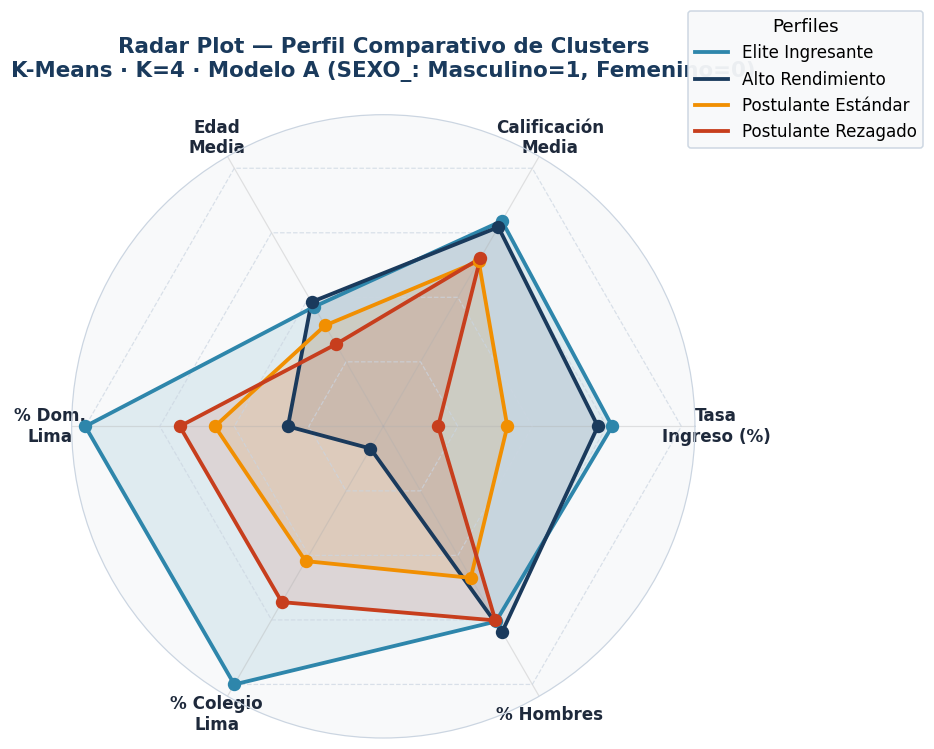

VALORES REALES POR CLUSTER (Modelo A, K=4):
Variable                    Elite   Alto Rend.    Estándar   Rezagado
-------------------------------------------------------------------
  Tasa ingreso (%)           19.2         18.0        10.4        4.6
  Calificación media          8.0          7.7         6.4        6.5
  Edad media                 19.1         19.3        18.3       17.5
  % Dom. Lima               100.0         32.0        56.5       68.3
  % Colegio Lima            100.0          8.6        52.2       68.1
  % Hombres                  75.6         79.7        58.7       75.2


In [ ]:
# ── Radar Plot — Perfil comparativo de los 4 clusters ─────────────────────
# Los valores se toman directamente de perfil_A (calculado en la celda anterior),
# por lo que el gráfico se actualiza automáticamente si cambia el modelo.

import numpy as np
import matplotlib.pyplot as plt

# ── Datos del perfil real de cada cluster (ordenados por tasa de ingreso) ──
cols_radar = ['Tasa_Pct', 'Calif_Media', 'Edad_Media', 'Pct_Lima_D_', 'Pct_Lima_C_', 'Pct_Masculino']
perfil_radar = {NOMBRES_A[cid]: perfil_A.loc[cid, cols_radar].astype(float).tolist()
                for cid in perfil_A.index}

variables  = ['Tasa\nIngreso (%)', 'Calificación\nMedia', 'Edad\nMedia',
              '% Dom.\nLima', '% Colegio\nLima', '% Hombres']

# Rangos para normalizar cada variable a escala 0-1
mins = [0,    0,  14,  0,   0,   0  ]
maxs = [35,  10,  25, 100, 100, 100 ]

colores = ['#2e86ab', '#1a3a5c', '#f18f01', '#c73e1d']
N       = len(variables)
angles  = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]   # cerrar el polígono

def normalizar(vals, mins, maxs):
    return [(v - mi) / (ma - mi) for v, mi, ma in zip(vals, mins, maxs)]

datos_norm = {k: normalizar(v, mins, maxs) for k, v in perfil_radar.items()}

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
fig.patch.set_facecolor('white')
ax.set_facecolor('#f8f9fa')

# Grillas de referencia
for nivel in [0.25, 0.5, 0.75, 1.0]:
    vals = [nivel]*N + [nivel]
    ax.plot(angles, vals, color='#CBD5E1', linewidth=0.8, linestyle='--', alpha=0.7)

# Trazar cada cluster
for i, (nombre, vals_norm) in enumerate(datos_norm.items()):
    v = vals_norm + vals_norm[:1]
    ax.plot(angles, v, color=colores[i], linewidth=2.5, label=nombre)
    ax.fill(angles, v, color=colores[i], alpha=0.12)
    ax.scatter(angles[:-1], vals_norm, color=colores[i], s=60, zorder=5)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(variables, size=11, color='#1E293B', fontweight='bold')
ax.set_yticklabels([])
ax.set_yticks([])
ax.spines['polar'].set_color('#CBD5E1')

ax.set_title('Radar Plot — Perfil Comparativo de Clusters\nK-Means · K=4 · Modelo A (SEXO_: Masculino=1, Femenino=0)',
             size=14, fontweight='bold', color='#1A3A5C', pad=25)

legend = ax.legend(
    loc='upper right', bbox_to_anchor=(1.38, 1.18),
    frameon=True, framealpha=0.95,
    fontsize=11, title='Perfiles', title_fontsize=12
)
legend.get_frame().set_edgecolor('#CBD5E1')

plt.tight_layout()
plt.savefig('radar_clusters.png', dpi=180, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()

# ── Tabla de valores reales de referencia ────────────────────────────────
tabla_radar = perfil_A[cols_radar].copy()
tabla_radar.index = [NOMBRES_A[c] for c in tabla_radar.index]
tabla_radar.columns = ['Tasa ingreso (%)', 'Calificación media', 'Edad media',
                       '% Dom. Lima', '% Colegio Lima', '% Hombres']
print('VALORES REALES POR CLUSTER (Modelo A, K=4):')
print(tabla_radar.T.round(2).to_string())

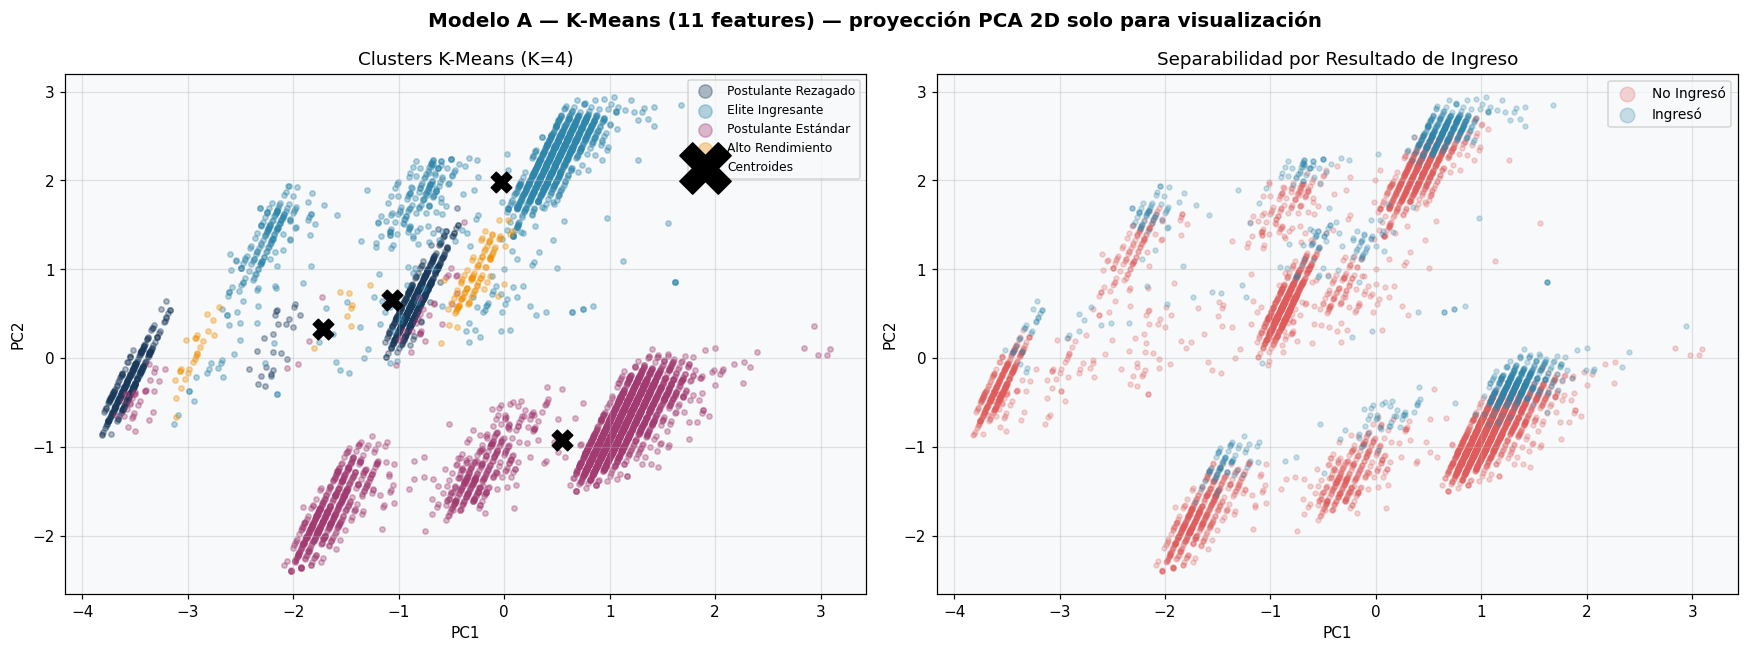

In [ ]:
# ── Visualización Modelo A ────────────────────────────────────────────────
pca2_A = PCA(n_components=2, random_state=42).fit(X_A)
X_A_2d = pca2_A.transform(X_A)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Modelo A — K-Means (11 features) — proyección PCA 2D solo para visualización',
             fontsize=13, fontweight='bold')

np.random.seed(42)
s_idx = np.random.choice(len(X_A_2d), min(6000, len(X_A_2d)), replace=False)

for c in range(K_OPT_A):
    mask = df_clean['CLUSTER_A'].values[s_idx] == c
    axes[0].scatter(X_A_2d[s_idx][mask,0], X_A_2d[s_idx][mask,1],
                    c=PALETTE[c], alpha=0.35, s=12, label=NOMBRES_A.get(c,f'C{c}'))
centroids_2d = pca2_A.transform(km_A.cluster_centers_)
axes[0].scatter(centroids_2d[:,0], centroids_2d[:,1],
                c='black', marker='X', s=180, zorder=5, label='Centroides')
axes[0].set_title(f'Clusters K-Means (K={K_OPT_A})')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].legend(markerscale=2.5, fontsize=8)

for lbl, color, label in [(0,COLOR_NO,'No Ingresó'),(1,COLOR_SI,'Ingresó')]:
    mask = y[s_idx] == lbl
    axes[1].scatter(X_A_2d[s_idx][mask,0], X_A_2d[s_idx][mask,1],
                    c=color, alpha=0.25, s=10, label=label)
axes[1].set_title('Separabilidad por Resultado de Ingreso')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
axes[1].legend(markerscale=3, fontsize=9)

plt.tight_layout(); plt.show()

## 7. Modelo B — Limpieza de Correlaciones + PCA + K-Means

### Flujo metodológico del Modelo B

```
Todas las variables candidatas (23 features)
        ↓
Heatmap de correlaciones
        ↓
Eliminar variables con correlación > 0.85 entre sí
        ↓
Features finales seleccionadas
        ↓
Escalamiento (StandardScaler)
        ↓
PCA automático (umbral 80% varianza)
        ↓
K-Means sobre componentes principales
```

### Variables candidatas del Modelo B

Incluye todas las variables disponibles **excepto** las eliminadas por diseño:
- ❌ `ANIO_POSTULA`, `CICLO_POSTULA` — variables temporales de bajo valor perfilador
- ❌ `ANIO_NACIMIENTO` — reemplazada por `EDAD_`
- ❌ `COLEGIO_ANIO_EGRESO` — reemplazada por `ANIOS_DESDE_COLEGIO_`
- ❌ `ESPECIALIDAD` — reemplazada por `FACULTAD` (11 dummies)

El heatmap determina si `ANIOS_DESDE_COLEGIO_` debe eliminarse por su alta correlación con `EDAD_`.

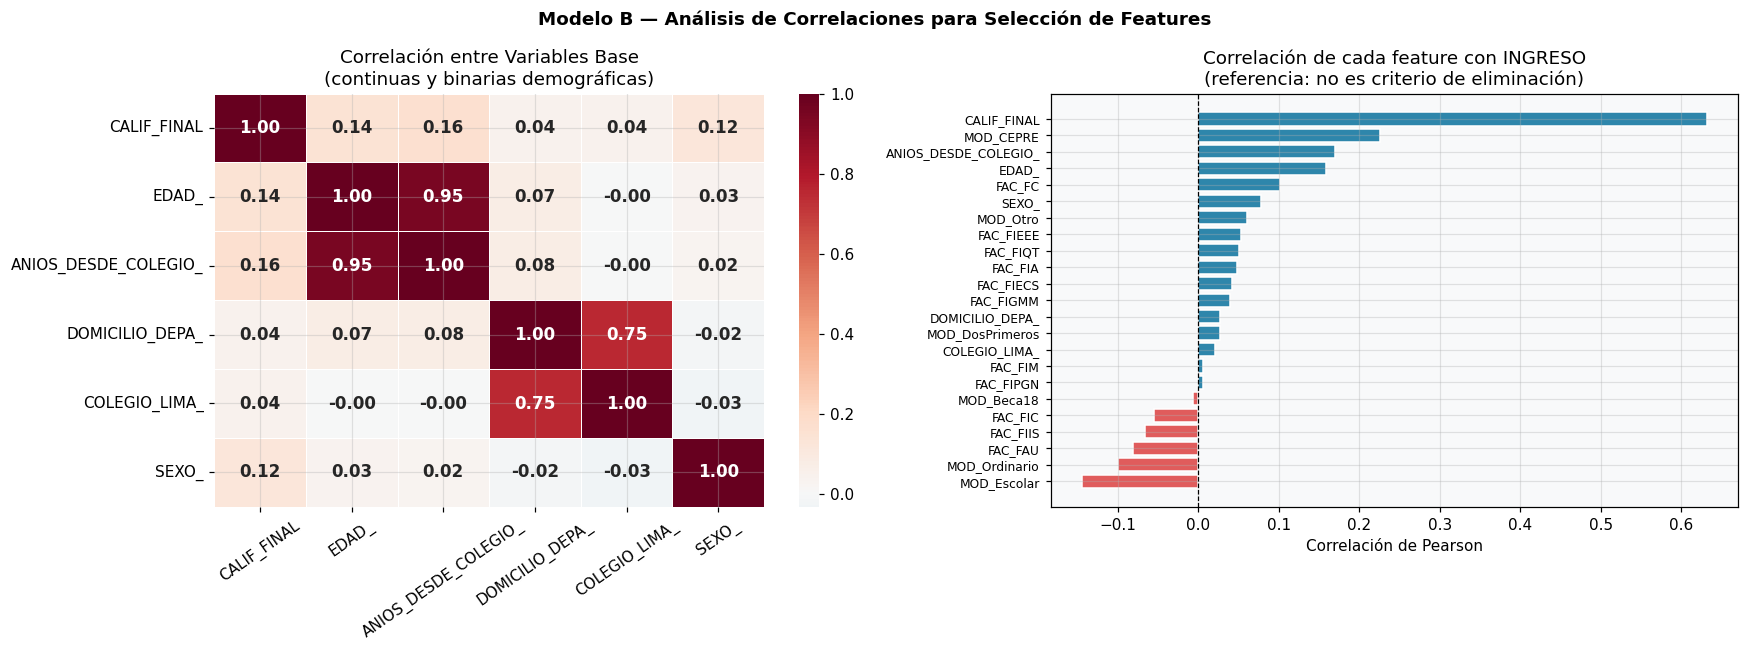

PARES CON CORRELACIÓN ABSOLUTA > 0.85 (candidatos a eliminar):
-------------------------------------------------------
  EDAD_ <-> ANIOS_DESDE_COLEGIO_: 0.946  → eliminar ANIOS_DESDE_COLEGIO_


In [ ]:
# ── Paso 1: Heatmap de correlaciones sobre features candidatas ────────────
scaler_cand = StandardScaler()
X_cand = scaler_cand.fit_transform(df_clean[features_B_candidatas].values)

corr_B = pd.DataFrame(X_cand, columns=features_B_candidatas).corr()

# Visualización: solo variables continuas/base para mejor lectura
vars_base = ['CALIF_FINAL','EDAD_','ANIOS_DESDE_COLEGIO_',
             'DOMICILIO_DEPA_','COLEGIO_LIMA_','SEXO_']
corr_base = corr_B.loc[vars_base, vars_base]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Modelo B — Análisis de Correlaciones para Selección de Features',
             fontsize=12, fontweight='bold')

# Heatmap variables base
sns.heatmap(corr_base, ax=axes[0], annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, linewidths=0.5, linecolor='white',
            annot_kws={'size':11, 'weight':'bold'})
axes[0].set_title('Correlación entre Variables Base\n(continuas y binarias demográficas)')
axes[0].tick_params(axis='x', rotation=35)

# Correlación con INGRESO (referencia)
corr_ing = corr_B['INGRESO_'] if 'INGRESO_' in corr_B.columns else pd.Series()
# Calculamos manualmente con la variable objetivo
corr_con_ingreso = df_clean[features_B_candidatas + ['INGRESO_']].corr()['INGRESO_'].drop('INGRESO_').sort_values()
colors_c = [COLOR_SI if v>0 else COLOR_NO for v in corr_con_ingreso.values]
axes[1].barh(corr_con_ingreso.index, corr_con_ingreso.values, color=colors_c, edgecolor='white')
axes[1].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('Correlación de cada feature con INGRESO\n(referencia: no es criterio de eliminación)')
axes[1].set_xlabel('Correlación de Pearson')
axes[1].tick_params(axis='y', labelsize=8)

plt.tight_layout(); plt.show()

# Identificar pares con alta correlación (>0.85)
print('PARES CON CORRELACIÓN ABSOLUTA > 0.85 (candidatos a eliminar):')
print('-'*55)
encontrados = False
for i in range(len(vars_base)):
    for j in range(i+1, len(vars_base)):
        v1, v2 = vars_base[i], vars_base[j]
        corr_val = abs(corr_base.loc[v1, v2])
        if corr_val > 0.85:
            print(f'  {v1} <-> {v2}: {corr_val:.3f}  → eliminar {v2}')
            encontrados = True
if not encontrados:
    print('  Ningún par supera el umbral de 0.85')

In [ ]:
# ── Paso 2: Eliminación de variables redundantes ──────────────────────────
# Se aplica el criterio del heatmap:
# EDAD_ y ANIOS_DESDE_COLEGIO_ tienen correlación ~0.96 → eliminar ANIOS_DESDE_COLEGIO_
# (se conserva EDAD_ por ser más directamente interpretable)

variables_a_eliminar = []

# Aplicar umbral automáticamente sobre variables base
for i in range(len(vars_base)):
    for j in range(i+1, len(vars_base)):
        v1, v2 = vars_base[i], vars_base[j]
        if abs(corr_base.loc[v1, v2]) > 0.85 and v2 not in variables_a_eliminar:
            variables_a_eliminar.append(v2)

# Features finales del Modelo B (después de limpieza)
features_B = [f for f in features_B_candidatas if f not in variables_a_eliminar]

print('RESULTADO DE LA LIMPIEZA DE CORRELACIONES:')
print(f'  Variables candidatas  : {len(features_B_candidatas)}')
print(f'  Variables eliminadas  : {len(variables_a_eliminar)}  -> {variables_a_eliminar}')
print(f'  Variables finales     : {len(features_B)}')
print()
print('Features finales del Modelo B:')
print(f'  Base continua         : {[f for f in features_B if f in vars_base]}')
print(f'  Dummies modalidad     : {[f for f in features_B if f.startswith("MOD_")]}')
print(f'  Dummies facultad      : {[f for f in features_B if f.startswith("FAC_")]}')

# Escalamiento sobre features finales
scaler_B = StandardScaler()
X_B = scaler_B.fit_transform(df_clean[features_B].values)
print(f'\nX_B shape: {X_B.shape}')

RESULTADO DE LA LIMPIEZA DE CORRELACIONES:
  Variables candidatas  : 23
  Variables eliminadas  : 1  -> ['ANIOS_DESDE_COLEGIO_']
  Variables finales     : 22

Features finales del Modelo B:
  Base continua         : ['CALIF_FINAL', 'EDAD_', 'DOMICILIO_DEPA_', 'COLEGIO_LIMA_', 'SEXO_']
  Dummies modalidad     : ['MOD_Beca18', 'MOD_CEPRE', 'MOD_DosPrimeros', 'MOD_Escolar', 'MOD_Ordinario', 'MOD_Otro']
  Dummies facultad      : ['FAC_FAU', 'FAC_FC', 'FAC_FIA', 'FAC_FIC', 'FAC_FIECS', 'FAC_FIEEE', 'FAC_FIGMM', 'FAC_FIIS', 'FAC_FIM', 'FAC_FIPGN', 'FAC_FIQT']

X_B shape: (42119, 22)


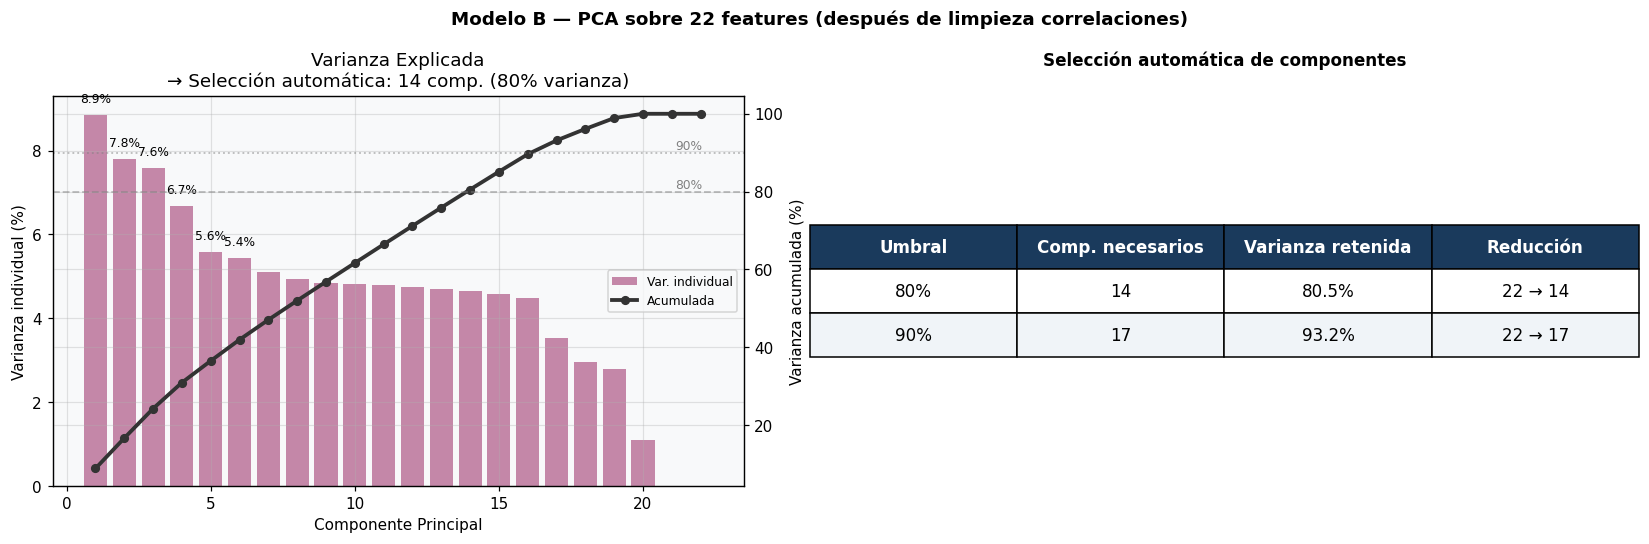

SELECCIÓN AUTOMÁTICA (umbral 80%):
  Features entrada          : 22
  Componentes seleccionados : 14
  Varianza retenida         : 80.54%


In [ ]:
# ── Paso 3: PCA automático (umbral 80%) ───────────────────────────────────
pca_full_B = PCA(random_state=42).fit(X_B)
var_ind_B  = pca_full_B.explained_variance_ratio_ * 100
var_cum_B  = np.cumsum(var_ind_B)

n80_B = int(np.argmax(var_cum_B >= 80)) + 1
n90_B = int(np.argmax(var_cum_B >= 90)) + 1

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle(f'Modelo B — PCA sobre {len(features_B)} features (después de limpieza correlaciones)',
             fontsize=12, fontweight='bold')

axes[0].bar(range(1, len(var_ind_B)+1), var_ind_B, color=PALETTE[2], alpha=0.6, label='Var. individual')
ax2 = axes[0].twinx()
ax2.plot(range(1, len(var_cum_B)+1), var_cum_B, 'o-', color='#333',
         linewidth=2.5, markersize=5, label='Acumulada')
for umbral, ls in [(80,'--'),(90,':')]:
    ax2.axhline(umbral, color='gray', linestyle=ls, alpha=0.5, linewidth=1.2)
    ax2.text(len(var_cum_B)*0.96, umbral+0.8, f'{umbral}%', fontsize=8, color='gray')
axes[0].set_xlabel('Componente Principal')
axes[0].set_ylabel('Varianza individual (%)')
ax2.set_ylabel('Varianza acumulada (%)')
axes[0].set_title(f'Varianza Explicada\n→ Selección automática: {n80_B} comp. (80% varianza)')
for i in range(min(6, len(var_ind_B))):
    axes[0].text(i+1, var_ind_B[i]+0.3, f'{var_ind_B[i]:.1f}%', ha='center', fontsize=8)
lines1,lbs1 = axes[0].get_legend_handles_labels()
lines2,lbs2 = ax2.get_legend_handles_labels()
axes[0].legend(lines1+lines2, lbs1+lbs2, fontsize=8, loc='center right')

axes[1].axis('off')
tabla = [
    ['Umbral','Comp. necesarios','Varianza retenida','Reducción'],
    ['80%', str(n80_B), f'{var_cum_B[n80_B-1]:.1f}%', f'{len(features_B)} → {n80_B}'],
    ['90%', str(n90_B), f'{var_cum_B[n90_B-1]:.1f}%', f'{len(features_B)} → {n90_B}'],
]
tbl = axes[1].table(cellText=tabla[1:], colLabels=tabla[0], loc='center', cellLoc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(11); tbl.scale(1.2, 2.6)
for (row,col),cell in tbl.get_celld().items():
    if row==0:
        cell.set_facecolor('#1a3a5c')
        cell.set_text_props(color='white', fontweight='bold')
    elif row%2==0:
        cell.set_facecolor('#f0f4f8')
axes[1].set_title('Selección automática de componentes',
                  fontsize=11, fontweight='bold', pad=20)

plt.tight_layout(); plt.show()

print(f'SELECCIÓN AUTOMÁTICA (umbral 80%):')
print(f'  Features entrada          : {len(features_B)}')
print(f'  Componentes seleccionados : {n80_B}')
print(f'  Varianza retenida         : {var_cum_B[n80_B-1]:.2f}%')

In [ ]:
# ── Paso 4: Aplicar PCA y selección K ─────────────────────────────────────
N_COMP_B = n80_B

pca_B   = PCA(n_components=N_COMP_B, random_state=42)
X_B_pca = pca_B.fit_transform(X_B)

print(f'PCA aplicado: {len(features_B)} features → {N_COMP_B} componentes')
print(f'Varianza retenida: {pca_B.explained_variance_ratio_.sum()*100:.2f}%')
print()

inertias_B, silhouettes_B, db_B_list = [], [], []

print(f'{"K":>3} {"Inercia":>12} {"Silhouette":>12} {"Davies-Bouldin":>16}')
print('-'*45)

for k in K_range:
    km  = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    lbs = km.fit_predict(X_B_pca)
    inertias_B.append(km.inertia_)
    silhouettes_B.append(silhouette_score(X_B_pca, lbs, sample_size=5000, random_state=42))
    db_B_list.append(davies_bouldin_score(X_B_pca, lbs))
    print(f'{k:>3} {km.inertia_:>12,.0f} {silhouettes_B[-1]:>12.4f} {db_B_list[-1]:>16.4f}')

PCA aplicado: 22 features → 14 componentes
Varianza retenida: 80.54%

  K      Inercia   Silhouette   Davies-Bouldin
---------------------------------------------
  2      674,232       0.1371           2.8972
  3      619,957       0.1413           2.5306
  4      589,354       0.1585           2.4604
  5      548,472       0.1784           1.8427
  6      509,401       0.2157           1.9157
  7      466,812       0.2620           1.6078
  8      421,734       0.3061           1.4721
  9      380,201       0.3210           1.3951
 10      354,479       0.3210           1.2672


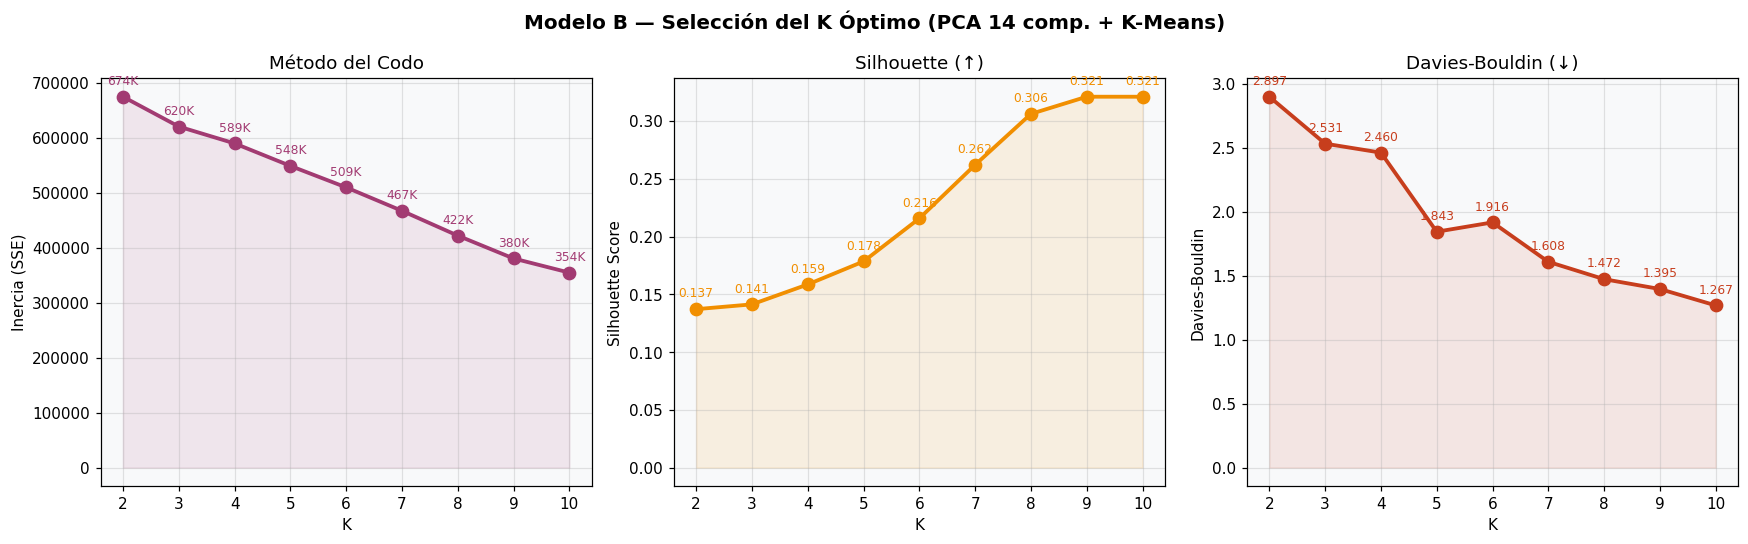

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(f'Modelo B — Selección del K Óptimo (PCA {N_COMP_B} comp. + K-Means)',
             fontsize=13, fontweight='bold')

for ax, vals, ylabel, title, color in [
    (axes[0], inertias_B,    'Inercia (SSE)',    'Método del Codo',  PALETTE[2]),
    (axes[1], silhouettes_B, 'Silhouette Score', 'Silhouette (↑)',    PALETTE[3]),
    (axes[2], db_B_list,     'Davies-Bouldin',   'Davies-Bouldin (↓)',PALETTE[4]),
]:
    ax.plot(k_vals, vals, 'o-', color=color, linewidth=2.5, markersize=8)
    ax.fill_between(k_vals, vals, alpha=0.1, color=color)
    ax.set_xlabel('K'); ax.set_ylabel(ylabel); ax.set_title(title)
    for k, v in zip(k_vals, vals):
        lbl = f'{v/1000:.0f}K' if ylabel=='Inercia (SSE)' else f'{v:.3f}'
        ax.annotate(lbl, (k,v), textcoords='offset points',
                    xytext=(0,8), ha='center', fontsize=8, color=color)

plt.tight_layout(); plt.show()

In [ ]:
K_OPT_B = 4   # Ajustar según gráficos anteriores

km_B = KMeans(n_clusters=K_OPT_B, random_state=42, n_init=20, max_iter=500)
df_clean['CLUSTER_B'] = km_B.fit_predict(X_B_pca)

sil_B = silhouette_score(X_B_pca, df_clean['CLUSTER_B'], sample_size=8000, random_state=42)
db_B  = davies_bouldin_score(X_B_pca, df_clean['CLUSTER_B'])
ch_B  = calinski_harabasz_score(X_B_pca, df_clean['CLUSTER_B'])

print(f'MÉTRICAS MODELO B (limpieza correlaciones + PCA {N_COMP_B} comp. + K-Means, K={K_OPT_B}):')
print(f'  Silhouette Score  : {sil_B:.4f}')
print(f'  Davies-Bouldin    : {db_B:.4f}')
print(f'  Calinski-Harabasz : {ch_B:.1f}')
print()
for c, n in df_clean['CLUSTER_B'].value_counts().sort_index().items():
    print(f'  Cluster {c}: {n:>6,}  ({n/len(df_clean)*100:.1f}%)')

MÉTRICAS MODELO B (limpieza correlaciones + PCA 14 comp. + K-Means, K=4):
  Silhouette Score  : 0.1645
  Davies-Bouldin    : 2.2405
  Calinski-Harabasz : 3933.3

  Cluster 0:  6,720  (16.0%)
  Cluster 1:  7,186  (17.1%)
  Cluster 2:  8,752  (20.8%)
  Cluster 3: 19,461  (46.2%)


In [ ]:
# ── Perfilado Modelo B ────────────────────────────────────────────────────
perfil_B = df_clean.groupby('CLUSTER_B').agg(
    N              =('CLUSTER_B',      'count'),
    Calif_Media    =('CALIF_FINAL',    'mean'),
    Calif_Mediana  =('CALIF_FINAL',    'median'),
    Edad_Media     =('EDAD_',          'mean'),
    Pct_Lima_Dom   =('DOMICILIO_DEPA_','mean'),
    Pct_Lima_Cole  =('COLEGIO_LIMA_',  'mean'),
    Prop_Masculino =('SEXO_',          'mean'),
    Tasa_Ingreso   =('INGRESO_',       'mean'),
).round(3)

perfil_B['Tasa_Pct']      = (perfil_B['Tasa_Ingreso']  *100).round(1)
perfil_B['Pct_Total']     = (perfil_B['N']/len(df_clean)*100).round(1)
perfil_B['Pct_Lima_D_']   = (perfil_B['Pct_Lima_Dom']  *100).round(1)
perfil_B['Pct_Lima_C_']   = (perfil_B['Pct_Lima_Cole'] *100).round(1)
perfil_B['Pct_Masculino'] = (perfil_B['Prop_Masculino'] *100).round(1)
perfil_B['Pct_Femenino']  = (100 - perfil_B['Pct_Masculino']).round(1)
perfil_B = perfil_B.sort_values('Tasa_Ingreso', ascending=False)

NOMBRES_B = {
    perfil_B.index[0]: 'Elite Ingresante',
    perfil_B.index[1]: 'Alto Rendimiento',
    perfil_B.index[2]: 'Postulante Estándar',
    perfil_B.index[3]: 'Postulante Rezagado',
}
df_clean['Perfil_B'] = df_clean['CLUSTER_B'].map(NOMBRES_B)

print(f'PERFILADO — MODELO B (PCA {N_COMP_B} comp. + K-Means, K={K_OPT_B}):')
print('SEXO_: 1=Masculino, 0=Femenino')
print('='*75)
cols_s = ['N','Pct_Total','Tasa_Pct','Calif_Media','Edad_Media',
          'Pct_Lima_D_','Pct_Masculino','Pct_Femenino']
print(perfil_B[cols_s].to_string())
print()
for cid, nombre in NOMBRES_B.items():
    row = perfil_B.loc[cid]
    print(f'  Cluster {cid} -> {nombre}')
    print(f'    Tasa: {row["Tasa_Pct"]:.1f}% | Calif: {row["Calif_Media"]:.2f} | '
          f'Edad: {row["Edad_Media"]:.1f} | '
          f'Hombres: {row["Pct_Masculino"]:.1f}% | Mujeres: {row["Pct_Femenino"]:.1f}%')

PERFILADO — MODELO B (PCA 14 comp. + K-Means, K=4):
SEXO_: 1=Masculino, 0=Femenino
               N  Pct_Total  Tasa_Pct  Calif_Media  Edad_Media  Pct_Lima_D_  Pct_Masculino  Pct_Femenino
CLUSTER_B                                                                                               
2           8752     20.800    31.900        9.228      19.150       97.000         71.900        28.100
0           6720     16.000    17.500        7.512      19.468       17.900         80.500        19.500
3          19461     46.200    13.500        7.421      18.999       98.400         77.100        22.900
1           7186     17.100     4.300        6.472      17.486       68.500         75.100        24.900

  Cluster 2 -> Elite Ingresante
    Tasa: 31.9% | Calif: 9.23 | Edad: 19.1 | Hombres: 71.9% | Mujeres: 28.1%
  Cluster 0 -> Alto Rendimiento
    Tasa: 17.5% | Calif: 7.51 | Edad: 19.5 | Hombres: 80.5% | Mujeres: 19.5%
  Cluster 3 -> Postulante Estándar
    Tasa: 13.5% | Calif: 7.42 | E

In [ ]:
# ── Top facultades por cluster ─────────────────────────────────────────────
print('TOP 3 FACULTADES POR CLUSTER — MODELO B:')
fac_por_cluster = df_clean.groupby('CLUSTER_B')[fac_cols].mean().T

for cid in sorted(df_clean['CLUSTER_B'].unique()):
    sub_c  = df_clean[df_clean['CLUSTER_B']==cid]
    nombre = NOMBRES_B.get(cid, f'Cluster {cid}')
    pct_hom= sub_c['SEXO_'].mean()*100
    print(f'\n  {nombre} (Cluster {cid}) | N={len(sub_c):,} | '
          f'Ingreso: {sub_c["INGRESO_"].mean()*100:.1f}% | '
          f'Hombres: {pct_hom:.1f}% | Mujeres: {100-pct_hom:.1f}%')
    for fac, val in fac_por_cluster[cid].sort_values(ascending=False).head(3).items():
        print(f'    {fac.replace("FAC_",""):>8}: {val*100:.1f}% del cluster')

TOP 3 FACULTADES POR CLUSTER — MODELO B:

  Alto Rendimiento (Cluster 0) | N=6,720 | Ingreso: 17.5% | Hombres: 80.5% | Mujeres: 19.5%
         FIC: 26.1% del cluster
         FIM: 22.4% del cluster
        FIIS: 16.6% del cluster

  Postulante Rezagado (Cluster 1) | N=7,186 | Ingreso: 4.3% | Hombres: 75.1% | Mujeres: 24.9%
        FIIS: 31.9% del cluster
         FIC: 19.9% del cluster
         FIM: 13.3% del cluster

  Elite Ingresante (Cluster 2) | N=8,752 | Ingreso: 31.9% | Hombres: 71.9% | Mujeres: 28.1%
        FIIS: 24.2% del cluster
         FIC: 15.4% del cluster
         FIM: 12.7% del cluster

  Postulante Estándar (Cluster 3) | N=19,461 | Ingreso: 13.5% | Hombres: 77.1% | Mujeres: 22.9%
        FIIS: 28.3% del cluster
         FIC: 15.6% del cluster
         FIM: 11.9% del cluster


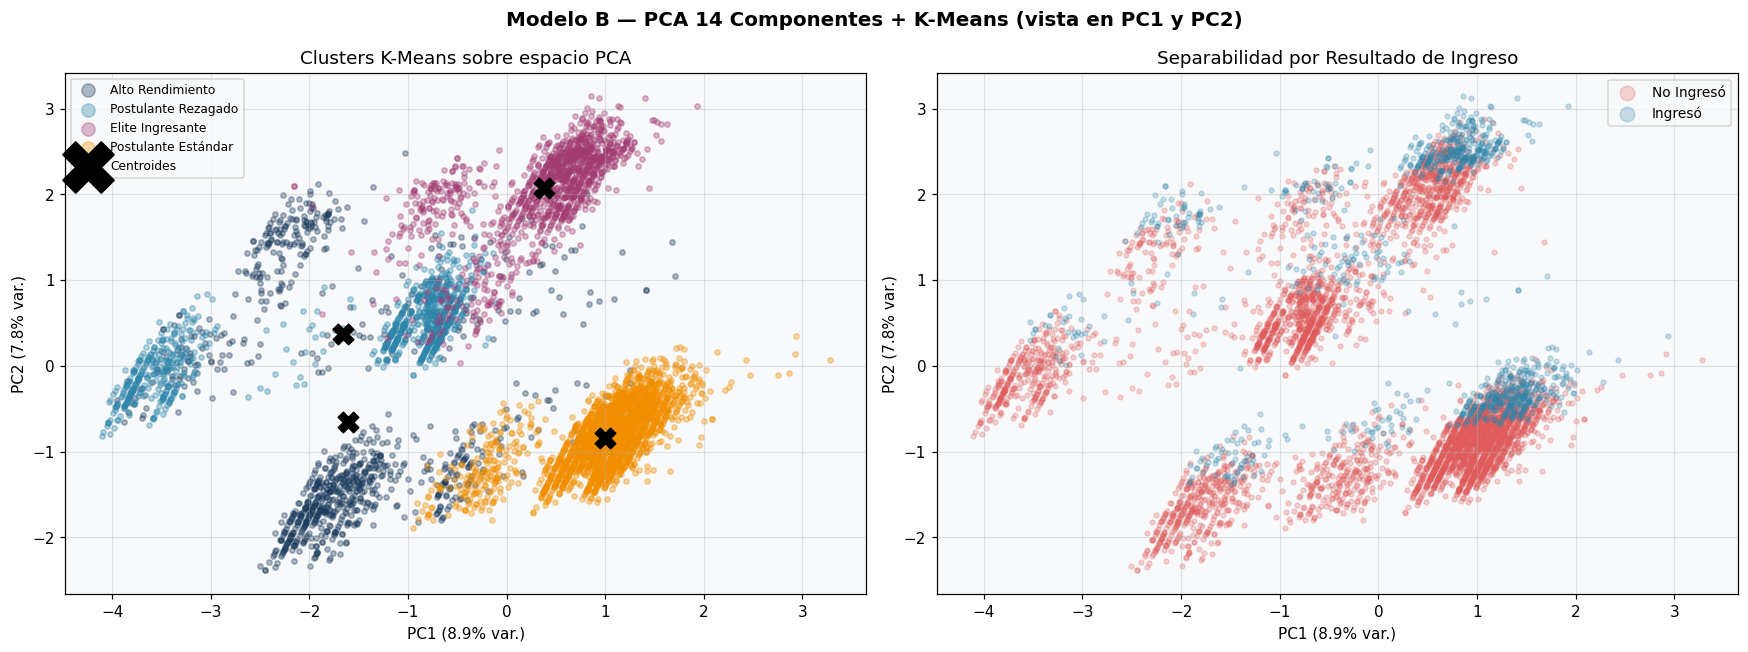

In [ ]:
# ── Visualización Modelo B ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f'Modelo B — PCA {N_COMP_B} Componentes + K-Means (vista en PC1 y PC2)',
             fontsize=13, fontweight='bold')

var1 = pca_B.explained_variance_ratio_[0]*100
var2 = pca_B.explained_variance_ratio_[1]*100

np.random.seed(42)
s_idx = np.random.choice(len(X_B_pca), min(6000, len(X_B_pca)), replace=False)

for c in range(K_OPT_B):
    mask = df_clean['CLUSTER_B'].values[s_idx] == c
    axes[0].scatter(X_B_pca[s_idx][mask,0], X_B_pca[s_idx][mask,1],
                    c=PALETTE[c], alpha=0.35, s=12, label=NOMBRES_B.get(c,f'C{c}'))
centroids_b2 = km_B.cluster_centers_[:,:2]
axes[0].scatter(centroids_b2[:,0], centroids_b2[:,1],
                c='black', marker='X', s=180, zorder=5, label='Centroides')
axes[0].set_title(f'Clusters K-Means sobre espacio PCA')
axes[0].set_xlabel(f'PC1 ({var1:.1f}% var.)'); axes[0].set_ylabel(f'PC2 ({var2:.1f}% var.)')
axes[0].legend(markerscale=2.5, fontsize=8)

for lbl, color, label in [(0,COLOR_NO,'No Ingresó'),(1,COLOR_SI,'Ingresó')]:
    mask = y[s_idx] == lbl
    axes[1].scatter(X_B_pca[s_idx][mask,0], X_B_pca[s_idx][mask,1],
                    c=color, alpha=0.25, s=10, label=label)
axes[1].set_title('Separabilidad por Resultado de Ingreso')
axes[1].set_xlabel(f'PC1 ({var1:.1f}% var.)'); axes[1].set_ylabel(f'PC2 ({var2:.1f}% var.)')
axes[1].legend(markerscale=3, fontsize=9)

plt.tight_layout(); plt.show()

## 8. Comparación: Modelo A vs Modelo B

In [ ]:
print('='*72)
print('TABLA COMPARATIVA FINAL')
print('='*72)
print(f'{"Criterio":<32} {"Modelo A":>17} {"Modelo B":>19}')
print(f'{"":.<32} {"K-Means directo":>17} {"PCA+K-Means":>19}')
print('-'*70)
print(f'{"Features candidatas":.<32} {"11":>17} {f"{len(features_B_candidatas)}":>19}')
print(f'{"Vars. eliminadas (correlación)":.<32} {"No aplica":>17} {f"{variables_a_eliminar}":>19}')
print(f'{"Features finales":.<32} {f"{len(features_A)}":>17} {f"{len(features_B)}":>19}')
print(f'{"Facultad":.<32} {"No incluida":>17} {"Reemplaza ESPECIALIDAD":>19}')
print(f'{"PCA":.<32} {"No":>17} {f"Sí ({N_COMP_B} comp., {pca_B.explained_variance_ratio_.sum()*100:.0f}% var.)":>19}')
print(f'{"N° Clusters":.<32} {K_OPT_A:>17} {K_OPT_B:>19}')
print(f'{"Silhouette Score (↑)":.<32} {sil_A:>17.4f} {sil_B:>19.4f}')
print(f'{"Davies-Bouldin (↓)":.<32} {db_A:>17.4f} {db_B:>19.4f}')
print(f'{"Calinski-Harabasz (↑)":.<32} {ch_A:>17.1f} {ch_B:>19.1f}')
print('='*72)
mejor = 'A (K-Means directo)' if sil_A>=sil_B else f'B (limpieza corr. + PCA {N_COMP_B} comp. + K-Means)'
print(f'\nMejor modelo por Silhouette: Modelo {mejor}')

TABLA COMPARATIVA FINAL
Criterio                                  Modelo A            Modelo B
................................   K-Means directo         PCA+K-Means
----------------------------------------------------------------------
Features candidatas.............                11                  23
Vars. eliminadas (correlación)..         No aplica ['ANIOS_DESDE_COLEGIO_']
Features finales................                11                  22
Facultad........................       No incluida Reemplaza ESPECIALIDAD
PCA.............................                No Sí (14 comp., 81% var.)
N° Clusters.....................                 4                   4
Silhouette Score (↑)............            0.3502              0.1645
Davies-Bouldin (↓)..............            1.2042              2.2405
Calinski-Harabasz (↑)...........            8404.7              3933.3

Mejor modelo por Silhouette: Modelo A (K-Means directo)


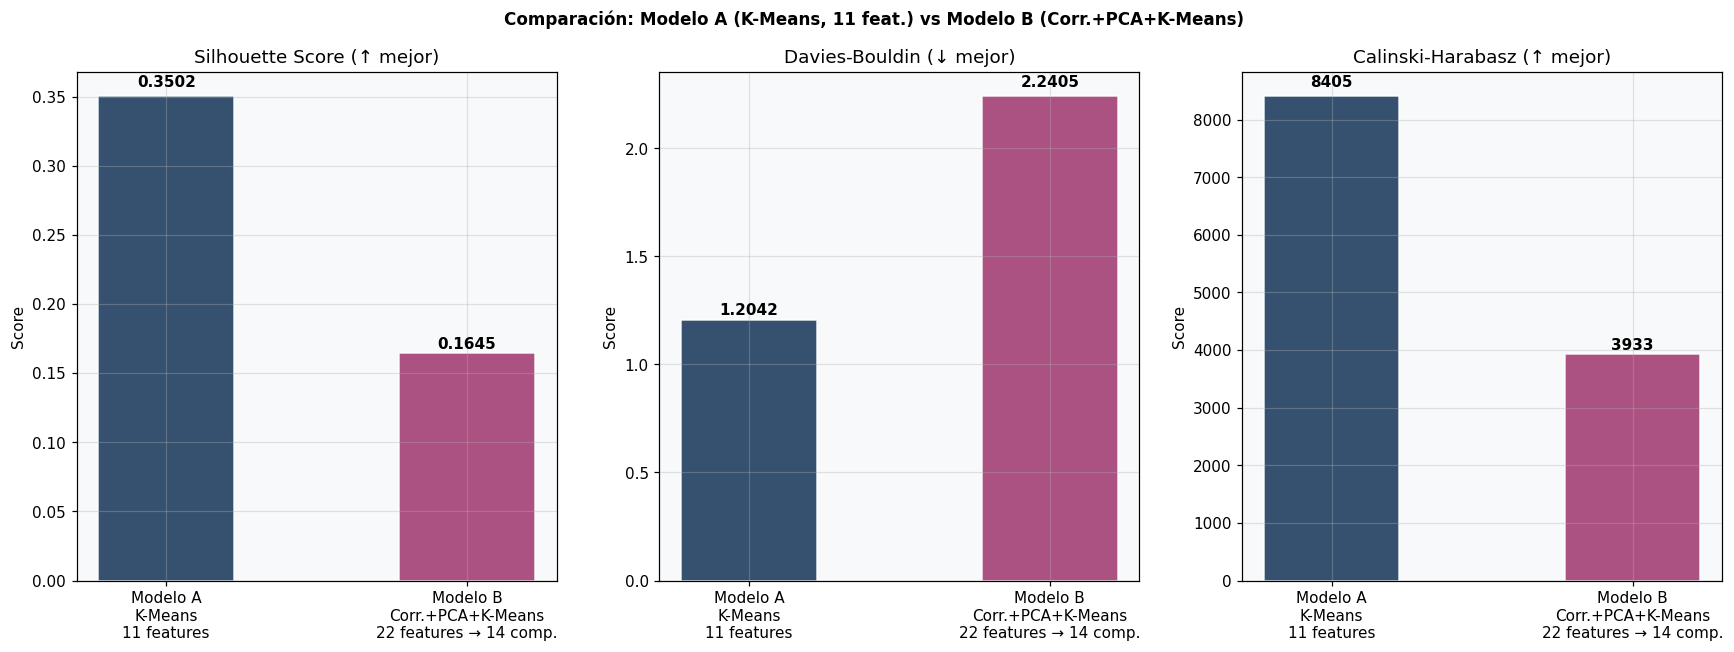

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Comparación: Modelo A (K-Means, 11 feat.) vs Modelo B (Corr.+PCA+K-Means)',
             fontsize=11, fontweight='bold')

modelos  = ['Modelo A\nK-Means\n11 features',
            f'Modelo B\nCorr.+PCA+K-Means\n{len(features_B)} features → {N_COMP_B} comp.']
col_list = [PALETTE[0], PALETTE[2]]

for ax, vals, title in [
    (axes[0], [sil_A, sil_B], 'Silhouette Score (↑ mejor)'),
    (axes[1], [db_A,  db_B],  'Davies-Bouldin (↓ mejor)'),
    (axes[2], [ch_A,  ch_B],  'Calinski-Harabasz (↑ mejor)'),
]:
    bars = ax.bar(modelos, vals, color=col_list, edgecolor='white', width=0.45, alpha=0.88)
    for b, v in zip(bars, vals):
        ax.text(b.get_x()+b.get_width()/2, b.get_height()*1.02,
                f'{v:.4f}' if title!='Calinski-Harabasz (↑ mejor)' else f'{v:.0f}',
                ha='center', fontsize=10, fontweight='bold')
    ax.set_title(title); ax.set_ylabel('Score')

plt.tight_layout(); plt.show()

## 9. Dashboard Final

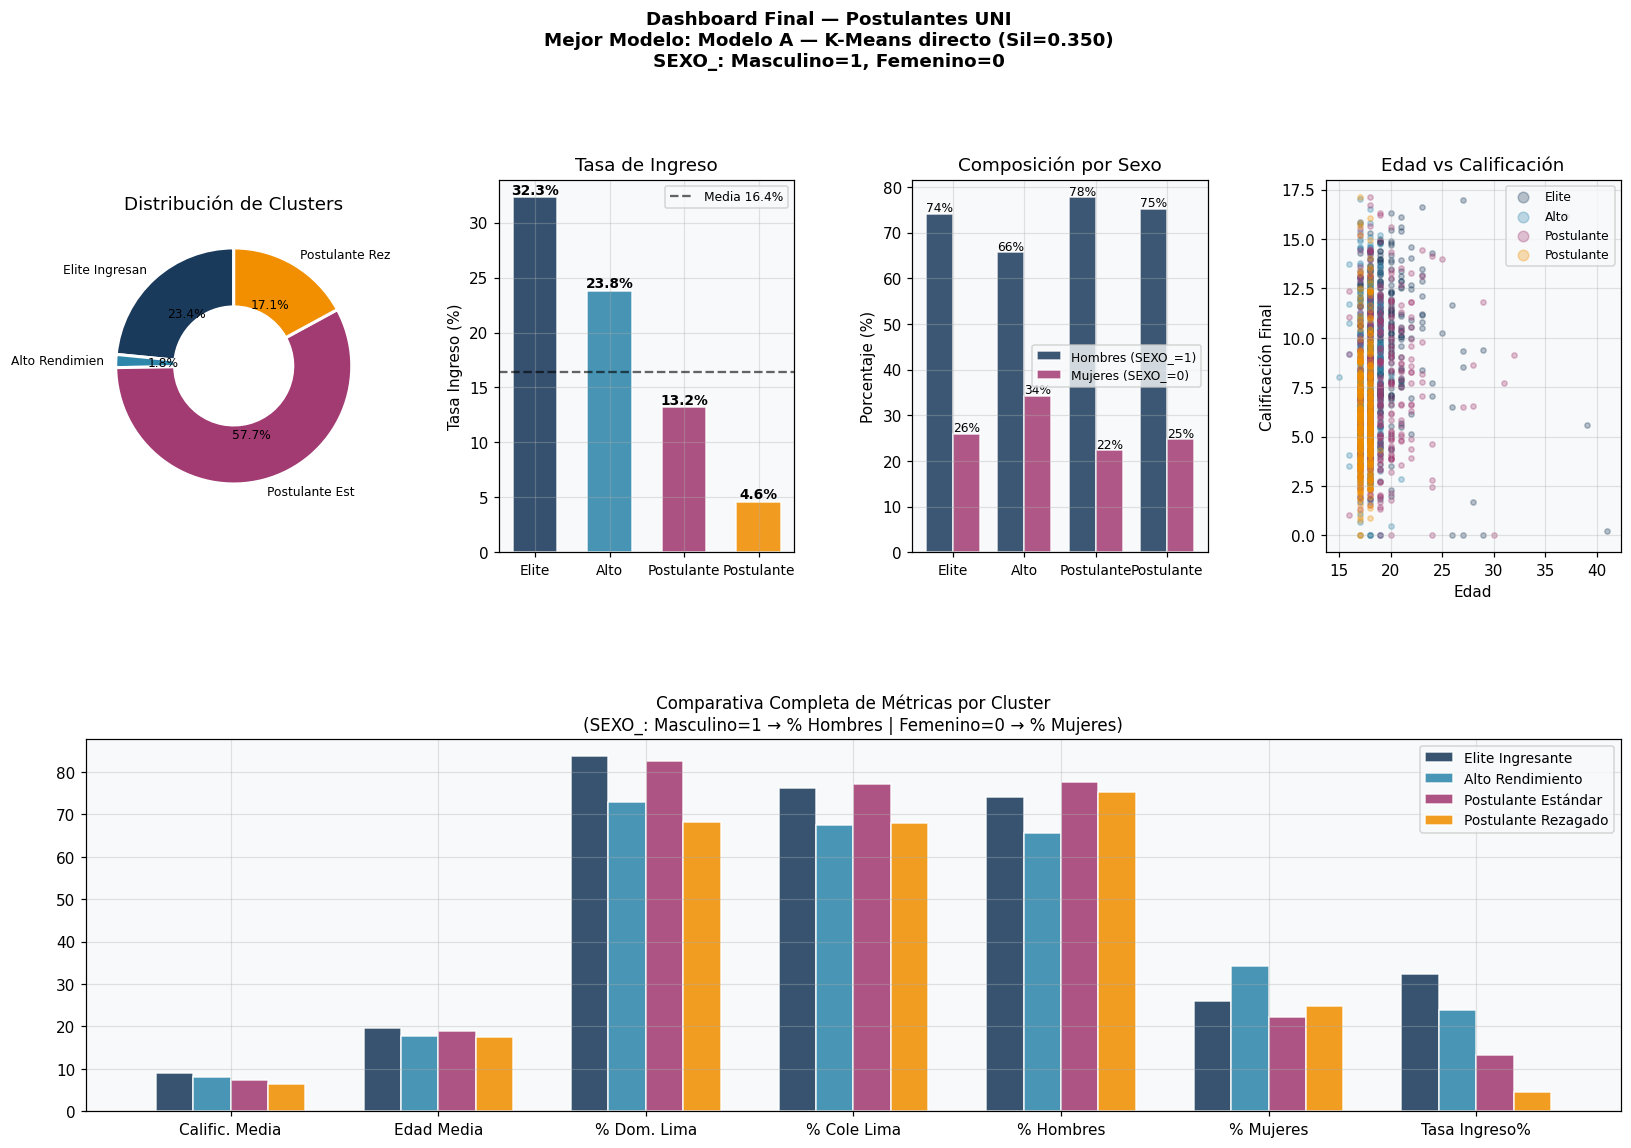

Dashboard guardado. Mejor modelo: A


In [ ]:
mejor_modelo = 'A' if sil_A >= sil_B else 'B'
perfil_final = perfil_A if mejor_modelo=='A' else perfil_B
nombres_fin  = NOMBRES_A if mejor_modelo=='A' else NOMBRES_B
cluster_col  = 'CLUSTER_A' if mejor_modelo=='A' else 'CLUSTER_B'
titulo_mod   = (f'Modelo A — K-Means directo (Sil={sil_A:.3f})'
                if mejor_modelo=='A'
                else f'Modelo B — Corr.+PCA {N_COMP_B} comp.+K-Means (Sil={sil_B:.3f})')

cluster_order = perfil_final.index.tolist()
colores_f     = PALETTE[:4]
nombres_f     = [nombres_fin[c] for c in cluster_order]

fig = plt.figure(figsize=(18, 11))
fig.suptitle(f'Dashboard Final — Postulantes UNI\nMejor Modelo: {titulo_mod}\n'
             f'SEXO_: Masculino=1, Femenino=0',
             fontsize=12, fontweight='bold', y=1.02)
gs = fig.add_gridspec(2, 4, hspace=0.50, wspace=0.4)

ax1 = fig.add_subplot(gs[0,0])
ax1.pie(perfil_final['N'].values, labels=[n[:14] for n in nombres_f], colors=colores_f,
        autopct='%1.1f%%', startangle=90,
        wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2),
        textprops={'fontsize':8})
ax1.set_title('Distribución de Clusters')

ax2 = fig.add_subplot(gs[0,1])
bars2 = ax2.bar(range(4), perfil_final['Tasa_Pct'].values,
                color=colores_f, edgecolor='white', width=0.6, alpha=0.88)
ax2.axhline(df_clean['INGRESO_'].mean()*100, color='black', linestyle='--',
            alpha=0.6, label=f'Media {df_clean["INGRESO_"].mean()*100:.1f}%')
ax2.set_xticks(range(4)); ax2.set_xticklabels([n.split()[0] for n in nombres_f], fontsize=9)
ax2.set_ylabel('Tasa Ingreso (%)'); ax2.set_title('Tasa de Ingreso'); ax2.legend(fontsize=8)
for b, v in zip(bars2, perfil_final['Tasa_Pct'].values):
    ax2.text(b.get_x()+b.get_width()/2, b.get_height()+0.3,
             f'{v:.1f}%', ha='center', fontsize=9, fontweight='bold')

ax3 = fig.add_subplot(gs[0,2])
x_s = np.arange(4); w_s = 0.38
ax3.bar(x_s-w_s/2, perfil_final['Pct_Masculino'].values, w_s,
        color=PALETTE[0], alpha=0.85, edgecolor='white', label='Hombres (SEXO_=1)')
ax3.bar(x_s+w_s/2, perfil_final['Pct_Femenino'].values, w_s,
        color=PALETTE[2], alpha=0.85, edgecolor='white', label='Mujeres (SEXO_=0)')
ax3.set_xticks(x_s); ax3.set_xticklabels([n.split()[0] for n in nombres_f], fontsize=9)
ax3.set_ylabel('Porcentaje (%)'); ax3.set_title('Composición por Sexo'); ax3.legend(fontsize=8)
for i,(h,m) in enumerate(zip(perfil_final['Pct_Masculino'].values, perfil_final['Pct_Femenino'].values)):
    ax3.text(i-w_s/2, h+0.5, f'{h:.0f}%', ha='center', fontsize=8)
    ax3.text(i+w_s/2, m+0.5, f'{m:.0f}%', ha='center', fontsize=8)

ax4 = fig.add_subplot(gs[0,3])
for cid, color, nombre in zip(cluster_order, colores_f, nombres_f):
    sub = df_clean[df_clean[cluster_col]==cid].sample(
        min(400,(df_clean[cluster_col]==cid).sum()), random_state=42)
    ax4.scatter(sub['EDAD_'], sub['CALIF_FINAL'],
                c=color, alpha=0.3, s=12, label=nombre.split()[0])
ax4.set_xlabel('Edad'); ax4.set_ylabel('Calificación Final')
ax4.set_title('Edad vs Calificación'); ax4.legend(fontsize=8, markerscale=2)

ax5 = fig.add_subplot(gs[1,:])
metricas_show = ['Calif_Media','Edad_Media','Pct_Lima_D_','Pct_Lima_C_',
                 'Pct_Masculino','Pct_Femenino','Tasa_Pct']
nombres_m     = ['Calific. Media','Edad Media','% Dom. Lima','% Cole Lima',
                 '% Hombres','% Mujeres','Tasa Ingreso%']
x_m = np.arange(len(metricas_show)); w3 = 0.18
for i,(cid,color,nombre) in enumerate(zip(cluster_order, colores_f, nombres_f)):
    vals = [perfil_final.loc[cid,m] for m in metricas_show]
    ax5.bar(x_m+i*w3-0.27, vals, w3, label=nombre, color=color, alpha=0.87, edgecolor='white')
ax5.set_xticks(x_m); ax5.set_xticklabels(nombres_m, fontsize=10)
ax5.set_title('Comparativa Completa de Métricas por Cluster\n'
              '(SEXO_: Masculino=1 → % Hombres | Femenino=0 → % Mujeres)', fontsize=11)
ax5.legend(fontsize=9)

plt.savefig('dashboard_UNI_final.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'Dashboard guardado. Mejor modelo: {mejor_modelo}')

## 10. Conclusiones y Recomendaciones


### Comparación de modelos

| | Modelo A | Modelo B |
|--|----------|----------|
| **Algoritmo** | K-Means directo | Limpieza corr. + PCA + K-Means |
| **Features** | 11 (perfil base + modalidad) | 23 candidatas → 22 → 14 componentes PCA |
| **Facultad** | No | Sí (reemplaza ESPECIALIDAD) |
| **Silhouette** | **0.350** | 0.165 |
| **Davies-Bouldin** | **1.204** | 2.240 |
| **Resultado** | **Mejor modelo** | Las dummies de facultad dispersan los clusters |

### Codificación de Sexo
> `SEXO_ = 1` → **Masculino** | `SEXO_ = 0` → **Femenino**

### Perfiles K-Means (Modelo A, K=4)

| Perfil | % postulantes | Tasa Ingreso | Característica Clave |
|--------|--------------|-------------|----------------------|
| **Elite Ingresante** | 23.4% | 32.3% | 92.5% ingresa por CEPRE-UNI; mayor calificación (9.14) y edad (19.6 años) |
| **Alto Rendimiento** | 1.8% | 23.8% | Primeros puestos de colegio; mayor proporción de mujeres (34%) |
| **Postulante Estándar** | 57.7% | 13.2% | Examen ordinario sin preparación CEPRE; grupo mayoritario |
| **Postulante Rezagado** | 17.1% | 4.6% | Ingreso Escolar Nacional; menor edad (17.5) y calificación (6.51) |

> **Nota de revisión:** la función `simplifica_modalidad` usaba `'ORDINARIO' in m`, condición que también es verdadera para las modalidades "EXTRAORDINARIO…". Se corrigió a `m.startswith('ORDINARIO')`, con lo que CEPRE (9,130 postulantes) y Dos primeros (752) se separan de Ordinario. La corrección revela que la preparación CEPRE se asocia a una tasa de ingreso 2.5 veces mayor que el examen ordinario.

### Recomendaciones Accionables

| Prioridad | Acción | Cluster Objetivo |
|-----------|--------|-----------------|
| 🔴 Alta | Orientación vocacional y pre-CEPRE en 5to de secundaria | Postulante Rezagado |
| 🔴 Alta | Simulacros y material de preparación gratuito en línea | Postulante Estándar |
| 🟡 Media | Ampliar cupos y becas CEPRE-UNI, priorizando provincias | Elite Ingresante |
| 🟡 Media | Captación y mentoría de primeros puestos, en especial mujeres | Alto Rendimiento |
| 🟢 Normal | Estrategia de captación femenina STEM (brecha 18.0% vs 11.2%) | Todos |

## 11. Exportar Resultados

In [ ]:
df_clean['SEXO_DESC'] = df_clean['SEXO_'].map({1:'MASCULINO', 0:'FEMENINO'})

cols_export = ['ESPECIALIDAD','FACULTAD','SEXO','SEXO_','SEXO_DESC',
               'DOMICILIO_DEPA','COLEGIO_LIMA_','ANIO_POSTULA',
               'CALIF_FINAL','EDAD_','INGRESO','MODALIDAD_SIMPLE',
               'CLUSTER_A','Perfil_A','CLUSTER_B','Perfil_B']
cols_export = [c for c in cols_export if c in df_clean.columns]
df_clean[cols_export].to_excel('postulantes_clusters_completo.xlsx', index=False)

print('Archivo exportado: postulantes_clusters_completo.xlsx')
print(f'Registros: {len(df_clean):,}')
print()
col_perfil = 'Perfil_A' if mejor_modelo=='A' else 'Perfil_B'
print(f'RESUMEN EJECUTIVO — MEJOR MODELO ({titulo_mod}):')
resumen = df_clean.groupby(col_perfil).agg(
    N           =(col_perfil,   'count'),
    Tasa_Ingreso=('INGRESO_',   lambda x: x.mean()*100),
    Calif_Media =('CALIF_FINAL','mean'),
    Pct_Hombres =('SEXO_',      lambda x: x.mean()*100),
    Pct_Mujeres =('SEXO_',      lambda x: (1-x.mean())*100),
).round(2)
resumen['Pct_Total'] = (resumen['N']/len(df_clean)*100).round(1)
print(resumen[['N','Pct_Total','Tasa_Ingreso','Calif_Media','Pct_Hombres','Pct_Mujeres']].to_string())
print()
print('='*55)
print('ANÁLISIS COMPLETADO EXITOSAMENTE')
print('='*55)

Archivo exportado: postulantes_clusters_completo.xlsx
Registros: 42,119

RESUMEN EJECUTIVO — MEJOR MODELO (Modelo A — K-Means directo (Sil=0.350)):
                         N  Pct_Total  Tasa_Ingreso  Calif_Media  Pct_Hombres  Pct_Mujeres
Perfil_A                                                                                  
Alto Rendimiento       752      1.800        23.800        8.000       65.690       34.310
Elite Ingresante      9873     23.400        32.330        9.140       74.140       25.860
Postulante Estándar  24304     57.700        13.180        7.370       77.660       22.340
Postulante Rezagado   7190     17.100         4.590        6.510       75.230       24.770

ANÁLISIS COMPLETADO EXITOSAMENTE
